# 08 — PTB-XL Error & Anomaly Labels Catalog (`ptbxl/error_labels.csv`)

This notebook documents and visualizes the **24-flag per-record error & data-quality label catalog** (`ptbxl/error_labels.csv`, generated by `ptbxl/generate_error_labels.py`) computed across **all `21,799` PTB-XL v1.0.3 ECGs**:

### Four Error Domains (`24` Binary `err_*` Flags)
1. **Metadata & Demographics (`4` flags)**:
   - `err_age_sentinel_300`: HIPAA `>89 yr` sentinel (`age == 300.0`)
   - `err_age_pediatric`: Pediatric/infant recording (`age < 18`)
   - `err_anthro_typo`: Implausible `height` / `weight` / `BMI` entry typo
   - `err_longitudinal_demo_conflict`: Within-patient `sex` flip, chronological `age` drop, or adult `height` jump `>10 cm`
2. **Clinical & SCP Label Quality (`7` flags)**:
   - `err_scp_zero_diagnostic`: `0` diagnostic SCP codes (e.g. `AFIB`/`PACE` silently mapped to `"NORM"`)
   - `err_scp_low_confidence`: Max diagnostic SCP likelihood `<= 35%`
   - `err_scp_norm_pathology_conflict`: `NORM` co-occurring with a pathological superclass
   - `err_scp_hierarchy_mismatch`: Alphabetical `_aggregate_class` contradicting max-weight `_pick_subclass`
   - `err_scp_unvalidated_autogen`: Machine-generated label set without human validation (`validated_by_human == False`)
   - `err_infarction_stadium_no_mi`: `infarction_stadium` populated without any `MI` SCP code
   - `err_rhythm_hr_mismatch`: Waveform heart rate contradicting `SBRAD` (`>68 BPM`) or `STACH` (`<92 BPM`)
3. **Annotated Signal Artifacts (`5` flags + `n_annotated_noisy_leads`)**:
   - `err_art_electrodes_problem`, `err_art_burst_noise`, `err_art_static_noise`, `err_art_baseline_drift`, `err_art_pacemaker`
4. **Quantitative Waveform & Delineation Defects (`8` flags across all `21,799` 100-Hz ECGs + Zenodo `7610236` segmentations)**:
   - `err_sig_nan_or_inf`, `err_sig_flatline_lead`, `err_sig_extreme_amplitude` (`>10 mV`), `err_sig_large_dc_offset` (`>0.5 mV`), `err_sig_lead_physics_violation` (Einthoven/Goldberger RMSE `>50 µV`), `err_sig_unannotated_defect`, `err_seg_high_uncertainty` (worst-lead entropy `>0.45`), `err_seg_lead_desync` (cross-lead R-peak corr `<0.25`)

### Actionable Severity Tiers
- **`0_clean`** (`keep`): Zero error or warning flags.
- **`1_minor_warning`** (`keep_with_cleaning`): Benign/correctable characteristics (`unvalidated_autogen`, `static_noise`, `baseline_drift`, `large_dc_offset`, `pediatric`, `pacemaker`, `hierarchy_mismatch`).
- **`2_moderate_anomaly`** (`review_or_downweight`): Metadata outliers/conflicts, low SCP certainty (`<=35%`), `burst_noise`, or elevated delineation uncertainty/desync.
- **`3_severe_error`** (`exclude`): Zero-diagnostic `"NORM"` trap, `NORM`+pathology conflict, `electrodes_problems`, flatlines, `>10 mV` rail spikes, or limb-physics corruption.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import wfdb

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 120, "savefig.bbox": "tight"})

_cwd = Path.cwd().resolve()
for _candidate in [_cwd, _cwd.parent, _cwd.parent.parent]:
    if (_candidate / "ptbxl" / "error_labels.csv").exists():
        REPO_ROOT = _candidate
        break
else:
    raise FileNotFoundError(f"Could not locate ptbxl/error_labels.csv from {_cwd}")

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from ptbxl import PTBXLDataset

PTBXL_DIR = REPO_ROOT / "ptbxl"
DATA_DIR = PTBXL_DIR / "data"
ERR_CSV = PTBXL_DIR / "error_labels.csv"

err_df = pd.read_csv(ERR_CSV, index_col="ecg_id")
err_df["error_tags"] = err_df["error_tags"].fillna("")
raw_df = pd.read_csv(DATA_DIR / "ptbxl_database.csv", index_col="ecg_id")

flag_cols = [c for c in err_df.columns if c.startswith("err_")]
print(f"Loaded {len(err_df):,} records × {len(flag_cols)} binary error flags from {ERR_CSV.name}")
err_df.head(5)

Loaded 21,799 records × 24 binary error flags from error_labels.csv


,strat_fold,err_age_sentinel_300,err_age_pediatric,err_anthro_typo,err_longitudinal_demo_conflict,err_scp_zero_diagnostic,err_scp_low_confidence,err_scp_norm_pathology_conflict,err_scp_hierarchy_mismatch,err_scp_unvalidated_autogen,...,err_sig_large_dc_offset,err_sig_lead_physics_violation,err_sig_unannotated_defect,err_seg_high_uncertainty,err_seg_lead_desync,n_annotated_noisy_leads,n_error_flags,severity_tier,recommended_action,error_tags
ecg_id,,,,,,,,,,,,,,,,,,,,,
1,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,7,1,1_minor_warning,keep_with_cleaning,art_static_noise
2,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0_clean,keep,
3,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0_clean,keep,
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,3,1,1_minor_warning,keep_with_cleaning,art_baseline_drift
5,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,3,1,1_minor_warning,keep_with_cleaning,art_baseline_drift


## 8.1 Full-Cohort Error Prevalence & Severity Tier Summary (`21,799` ECGs)

In [2]:
def domain_of(col: str) -> str:
    if col.startswith(("err_age_", "err_anthro_", "err_longitudinal_")):
        return "1. Metadata"
    if col.startswith(("err_scp_", "err_infarction_", "err_rhythm_")):
        return "2. Clinical / SCP Label"
    if col.startswith("err_art_"):
        return "3. Annotated Artifact"
    return "4. Waveform / Delineation"

summary_table = pd.DataFrame([
    {
        "flag": c,
        "domain": domain_of(c),
        "count": int(err_df[c].sum()),
        "pct_of_21799": round(float(err_df[c].mean() * 100), 2),
    }
    for c in flag_cols
]).sort_values(["domain", "count"], ascending=[True, False])

display(summary_table)

print("\n=== Severity Tier & Recommended Action Summary ===")
tier_summary = err_df.groupby(["severity_tier", "recommended_action"]).size().rename("count").reset_index()
tier_summary["pct"] = (tier_summary["count"] / len(err_df) * 100).round(2)
display(tier_summary)

,flag,domain,count,pct_of_21799
0,err_age_sentinel_300,1. Metadata,293,1.34
1,err_age_pediatric,1. Metadata,133,0.61
2,err_anthro_typo,1. Metadata,18,0.08
3,err_longitudinal_demo_conflict,1. Metadata,0,0.00
8,err_scp_unvalidated_autogen,2. Clinical / SCP Label,5743,26.35
7,err_scp_hierarchy_mismatch,2. Clinical / SCP Label,1932,8.86
5,err_scp_low_confidence,2. Clinical / SCP Label,1015,4.66
6,err_scp_norm_pathology_conflict,2. Clinical / SCP Label,445,2.04
4,err_scp_zero_diagnostic,2. Clinical / SCP Label,411,1.89
9,err_infarction_stadium_no_mi,2. Clinical / SCP Label,143,0.66



=== Severity Tier & Recommended Action Summary ===


,severity_tier,recommended_action,count,pct
0,0_clean,keep,10154,46.58
1,1_minor_warning,keep_with_cleaning,8036,36.86
2,2_moderate_anomaly,review_or_downweight,2695,12.36
3,3_severe_error,exclude,914,4.19


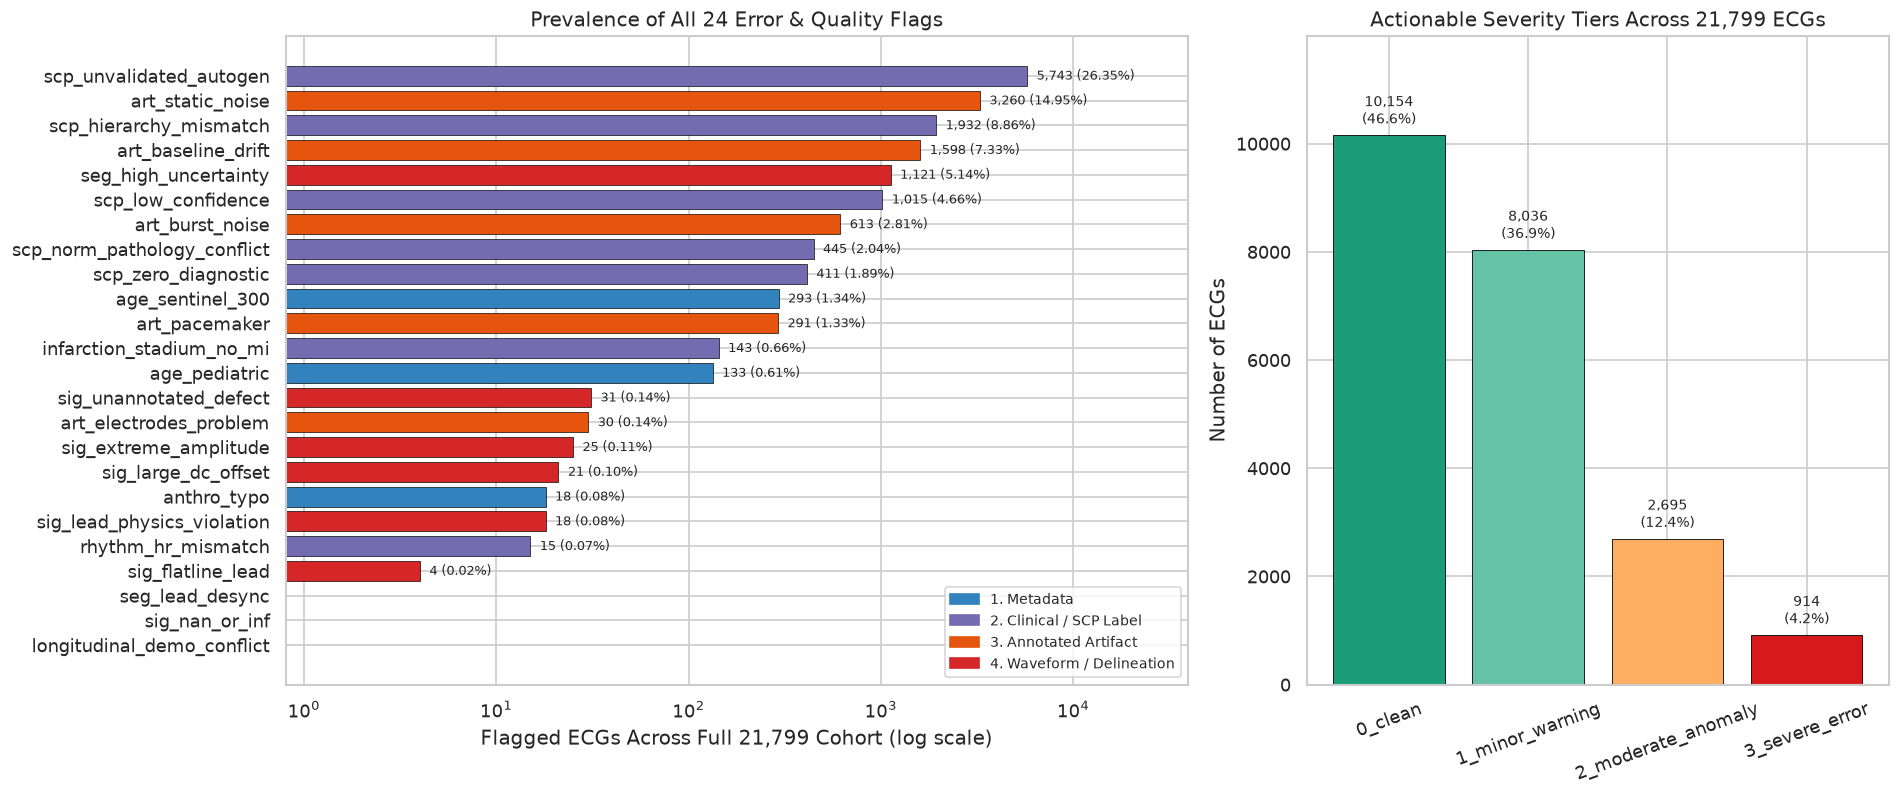

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.8), gridspec_kw={"width_ratios": [1.55, 1]})

# Left: All 24 error flags ranked by prevalence, colored by domain
plot_tbl = summary_table.sort_values("count", ascending=True)
dom_pal = {
    "1. Metadata": "#3182bd",
    "2. Clinical / SCP Label": "#756bb1",
    "3. Annotated Artifact": "#e6550d",
    "4. Waveform / Delineation": "#d62728",
}
bar_c = [dom_pal[d] for d in plot_tbl["domain"]]
axes[0].barh(plot_tbl["flag"].str.replace("^err_", "", regex=True), plot_tbl["count"], color=bar_c, edgecolor="black", lw=0.4)
axes[0].set_xscale("log")
axes[0].set_xlabel("Flagged ECGs Across Full 21,799 Cohort (log scale)")
axes[0].set_title("Prevalence of All 24 Error & Quality Flags")
for i, (cnt, pct) in enumerate(zip(plot_tbl["count"], plot_tbl["pct_of_21799"])):
    if cnt > 0:
        axes[0].text(cnt * 1.12, i, f"{cnt:,} ({pct:.2f}%)", va="center", fontsize=7.8)
axes[0].set_xlim(0.8, err_df.shape[0] * 1.8)
from matplotlib.patches import Patch
axes[0].legend(handles=[Patch(color=v, label=k) for k, v in dom_pal.items()], loc="lower right", fontsize=8.5)

# Right: Severity tier breakdown + n_error_flags distribution
tier_vc = err_df["severity_tier"].value_counts().sort_index()
tier_colors = ["#1b9e77", "#66c2a5", "#fdae61", "#d7191c"]
axes[1].bar(tier_vc.index, tier_vc.values, color=tier_colors, edgecolor="black", lw=0.5)
axes[1].set_ylabel("Number of ECGs")
axes[1].set_title("Actionable Severity Tiers Across 21,799 ECGs")
axes[1].tick_params(axis="x", rotation=20)
for i, v in enumerate(tier_vc.values):
    axes[1].text(i, v + 220, f"{v:,}\n({v/len(err_df)*100:.1f}%)", ha="center", fontsize=8.5)
axes[1].set_ylim(0, tier_vc.max() * 1.18)

plt.tight_layout()
plt.show()

## 8.2 Full-Cohort Discovery: Unannotated Waveform Defects & Error Co-occurrence

Scanning **all `21,799` waveforms** in `generate_error_labels.py` uncovered records with `err_sig_unannotated_defect == 1` — ECGs that had **zero metadata noise flags** (`static_noise`, `burst_noise`, `electrodes_problems` all `NaN`, so `PTBXLDataset(filter_noise=True)` kept them!) yet failed quantitative flatline, `>10 mV` spike, or limb-physics checks! Let's inspect them and visualize cross-error correlations.

Total unannotated waveform defects caught across all 21,799 ECGs: 31


,strat_fold,err_sig_flatline_lead,err_sig_extreme_amplitude,err_sig_lead_physics_violation,err_seg_high_uncertainty,error_tags
ecg_id,,,,,,
421,1,0,1,0,0,art_baseline_drift|sig_extreme_amplitude|sig_u...
710,3,0,1,0,0,sig_extreme_amplitude|sig_unannotated_defect
2166,6,0,0,1,0,sig_lead_physics_violation|sig_unannotated_defect
2525,6,0,0,1,0,scp_hierarchy_mismatch|sig_lead_physics_violat...
4753,5,0,1,0,1,art_baseline_drift|sig_extreme_amplitude|sig_l...
6017,7,0,0,1,0,age_sentinel_300|scp_hierarchy_mismatch|sig_le...
6816,9,0,1,0,1,age_sentinel_300|art_baseline_drift|sig_extrem...
6965,4,0,0,1,0,sig_lead_physics_violation|sig_unannotated_defect
7133,7,0,1,0,0,scp_unvalidated_autogen|sig_extreme_amplitude|...


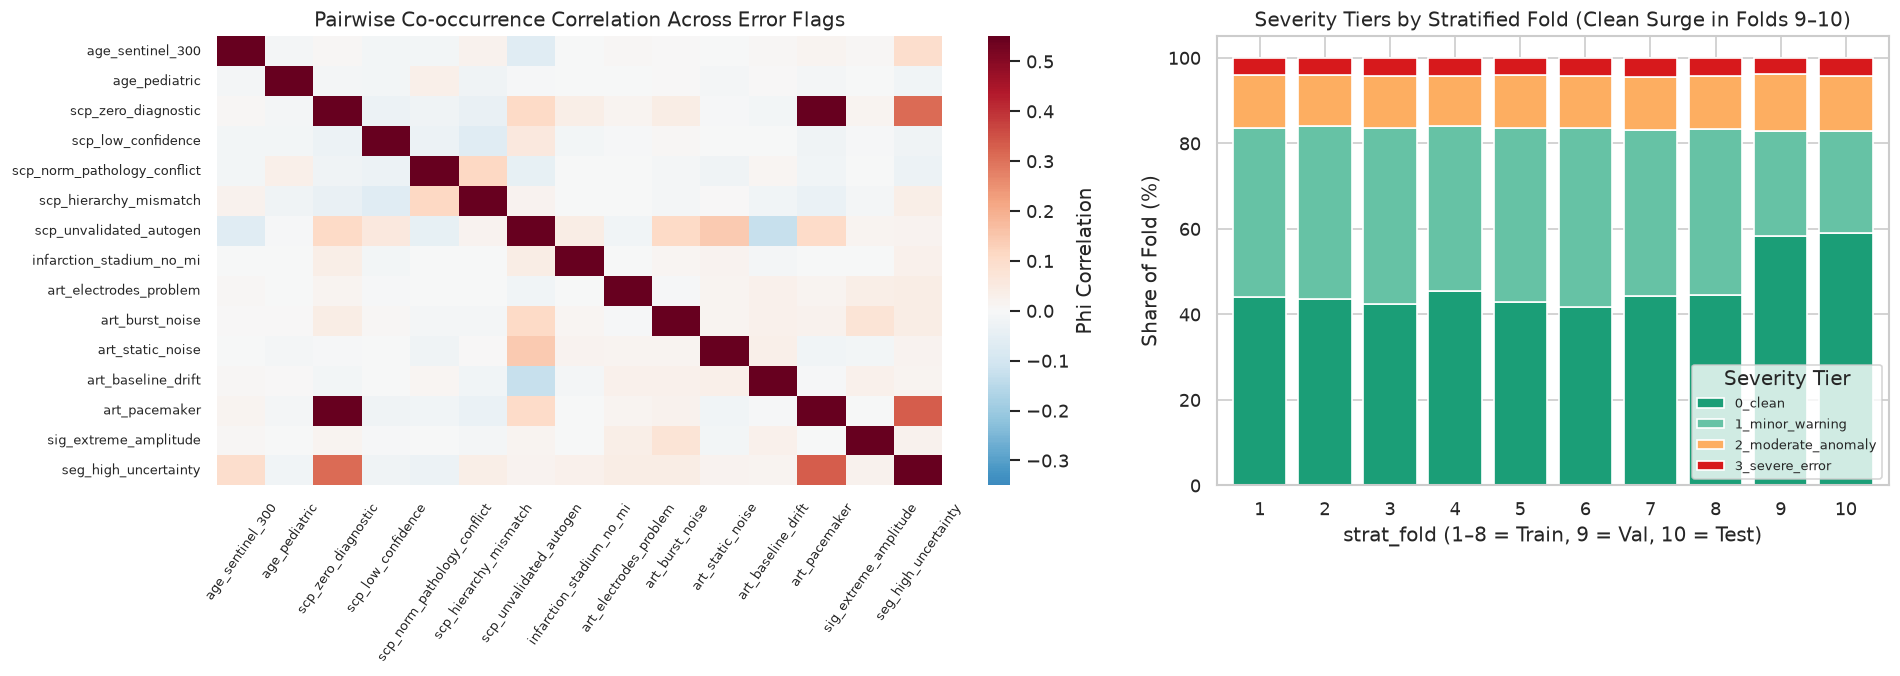

In [4]:
unannot_ids = err_df.index[err_df["err_sig_unannotated_defect"] == 1]
print(f"Total unannotated waveform defects caught across all 21,799 ECGs: {len(unannot_ids):,}")
display(
    err_df.loc[
        unannot_ids,
        ["strat_fold", "err_sig_flatline_lead", "err_sig_extreme_amplitude", "err_sig_lead_physics_violation", "err_seg_high_uncertainty", "error_tags"],
    ].head(12)
)

# Co-occurrence correlation among active flags (>= 25 occurrences)
active_cols = [c for c in flag_cols if err_df[c].sum() >= 25 and c != "err_sig_unannotated_defect"]
corr_mat = err_df[active_cols].corr()
corr_mat.index = [c[4:] for c in active_cols]
corr_mat.columns = [c[4:] for c in active_cols]

fig, axes = plt.subplots(1, 2, figsize=(16, 5.8), gridspec_kw={"width_ratios": [1.35, 1]})
sns.heatmap(corr_mat, cmap="RdBu_r", center=0, vmin=-0.35, vmax=0.55, ax=axes[0], cbar_kws={"label": "Phi Correlation"})
axes[0].set_title("Pairwise Co-occurrence Correlation Across Error Flags")
axes[0].tick_params(axis="x", rotation=55, labelsize=8)
axes[0].tick_params(axis="y", labelsize=8)

# Right: Severity Tier Share Across strat_fold 1..10
fold_tier = pd.crosstab(err_df["strat_fold"], err_df["severity_tier"], normalize="index") * 100
fold_tier.plot(kind="bar", stacked=True, color=tier_colors, ax=axes[1], width=0.82)
axes[1].set_xlabel("strat_fold (1–8 = Train, 9 = Val, 10 = Test)")
axes[1].set_ylabel("Share of Fold (%)")
axes[1].set_title("Severity Tiers by Stratified Fold (Clean Surge in Folds 9–10)")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="Severity Tier", fontsize=8, loc="lower right")

plt.tight_layout()
plt.show()

## 8.3 Using Error Labels Directly in `PTBXLDataset`

`PTBXLDataset` supports both **inspecting** error labels per sample (`load_error_labels=True`) and **filtering** by severity tier (`max_error_severity`) or specific error flags (`exclude_error_flags`):

In [5]:
# 1. Inspect error_labels dictionary attached to samples
ds_default = PTBXLDataset.train(load_error_labels=True)
sample0 = ds_default[0]
print("Sample error_labels dict keys:", list(sample0["error_labels"].keys()))
print("Sample[0] severity & tags    :", sample0["error_labels"]["severity_tier"], "|", sample0["error_labels"]["error_tags"])

# 2. Compare dataset sizes under progressive cleaning policies
ds_clean_severe = PTBXLDataset.train(max_error_severity=2)  # drops '3_severe_error' (0-diag NORM trap, flatlines, >10mV spikes, etc.)
ds_targeted = PTBXLDataset.train(
    exclude_error_flags=[
        "err_scp_zero_diagnostic",
        "err_sig_unannotated_defect",
        "err_scp_norm_pathology_conflict",
    ]
)
ds_strict_gold = PTBXLDataset.train(max_error_severity=0)   # strictly 0-flag human-validated clean records

comparison = pd.DataFrame([
    {"Configuration": "Default PTBXLDataset.train()", "Train Size": len(ds_default), "Num Classes": len(ds_default.class_names)},
    {"Configuration": "Targeted exclude (0-diag + unannotated signal + NORM conflict)", "Train Size": len(ds_targeted), "Num Classes": len(ds_targeted.class_names)},
    {"Configuration": "max_error_severity=2 (drop all 3_severe_error)", "Train Size": len(ds_clean_severe), "Num Classes": len(ds_clean_severe.class_names)},
    {"Configuration": "max_error_severity=0 (strictly 0-flag gold subset)", "Train Size": len(ds_strict_gold), "Num Classes": len(ds_strict_gold.class_names)},
])
display(comparison)

Sample error_labels dict keys: ['severity_tier', 'recommended_action', 'n_error_flags', 'n_annotated_noisy_leads', 'error_tags', 'flags']
Sample[0] severity & tags    : 0_clean | []


,Configuration,Train Size,Num Classes
0,Default PTBXLDataset.train(),14071,15
1,Targeted exclude (0-diag + unannotated signal ...,13471,15
2,max_error_severity=2 (drop all 3_severe_error),13471,15
3,max_error_severity=0 (strictly 0-flag gold sub...,7548,14


## 8.4 Waveform Plot Examples Across Error Labels & Severity Tiers

Below we visualize **12 real PTB-XL waveforms** directly indexed from `ptbxl/error_labels.csv`:
- **Gallery A (Waveform & Hardware Defects)**: Contrasting a `0_clean` reference against `err_sig_flatline_lead`, `err_sig_extreme_amplitude` (`>10 mV`), `err_sig_lead_physics_violation` (plotting `Lead II` vs `I + III` residual), `err_sig_unannotated_defect` (missed by metadata flags!), and `err_art_electrodes_problem`.
- **Gallery B (Label, Rhythm, Drift & Delineation Anomalies)**: Plotting `err_scp_zero_diagnostic` (`AFIB`/`PACE` mapped to `"NORM"`), `err_scp_norm_pathology_conflict`, `err_rhythm_hr_mismatch` (with detected R-peaks & actual BPM), `err_seg_high_uncertainty` (with Zenodo `7610236` entropy overlay), `err_sig_large_dc_offset` (raw uncentered mV offset), and `err_art_burst_noise`.

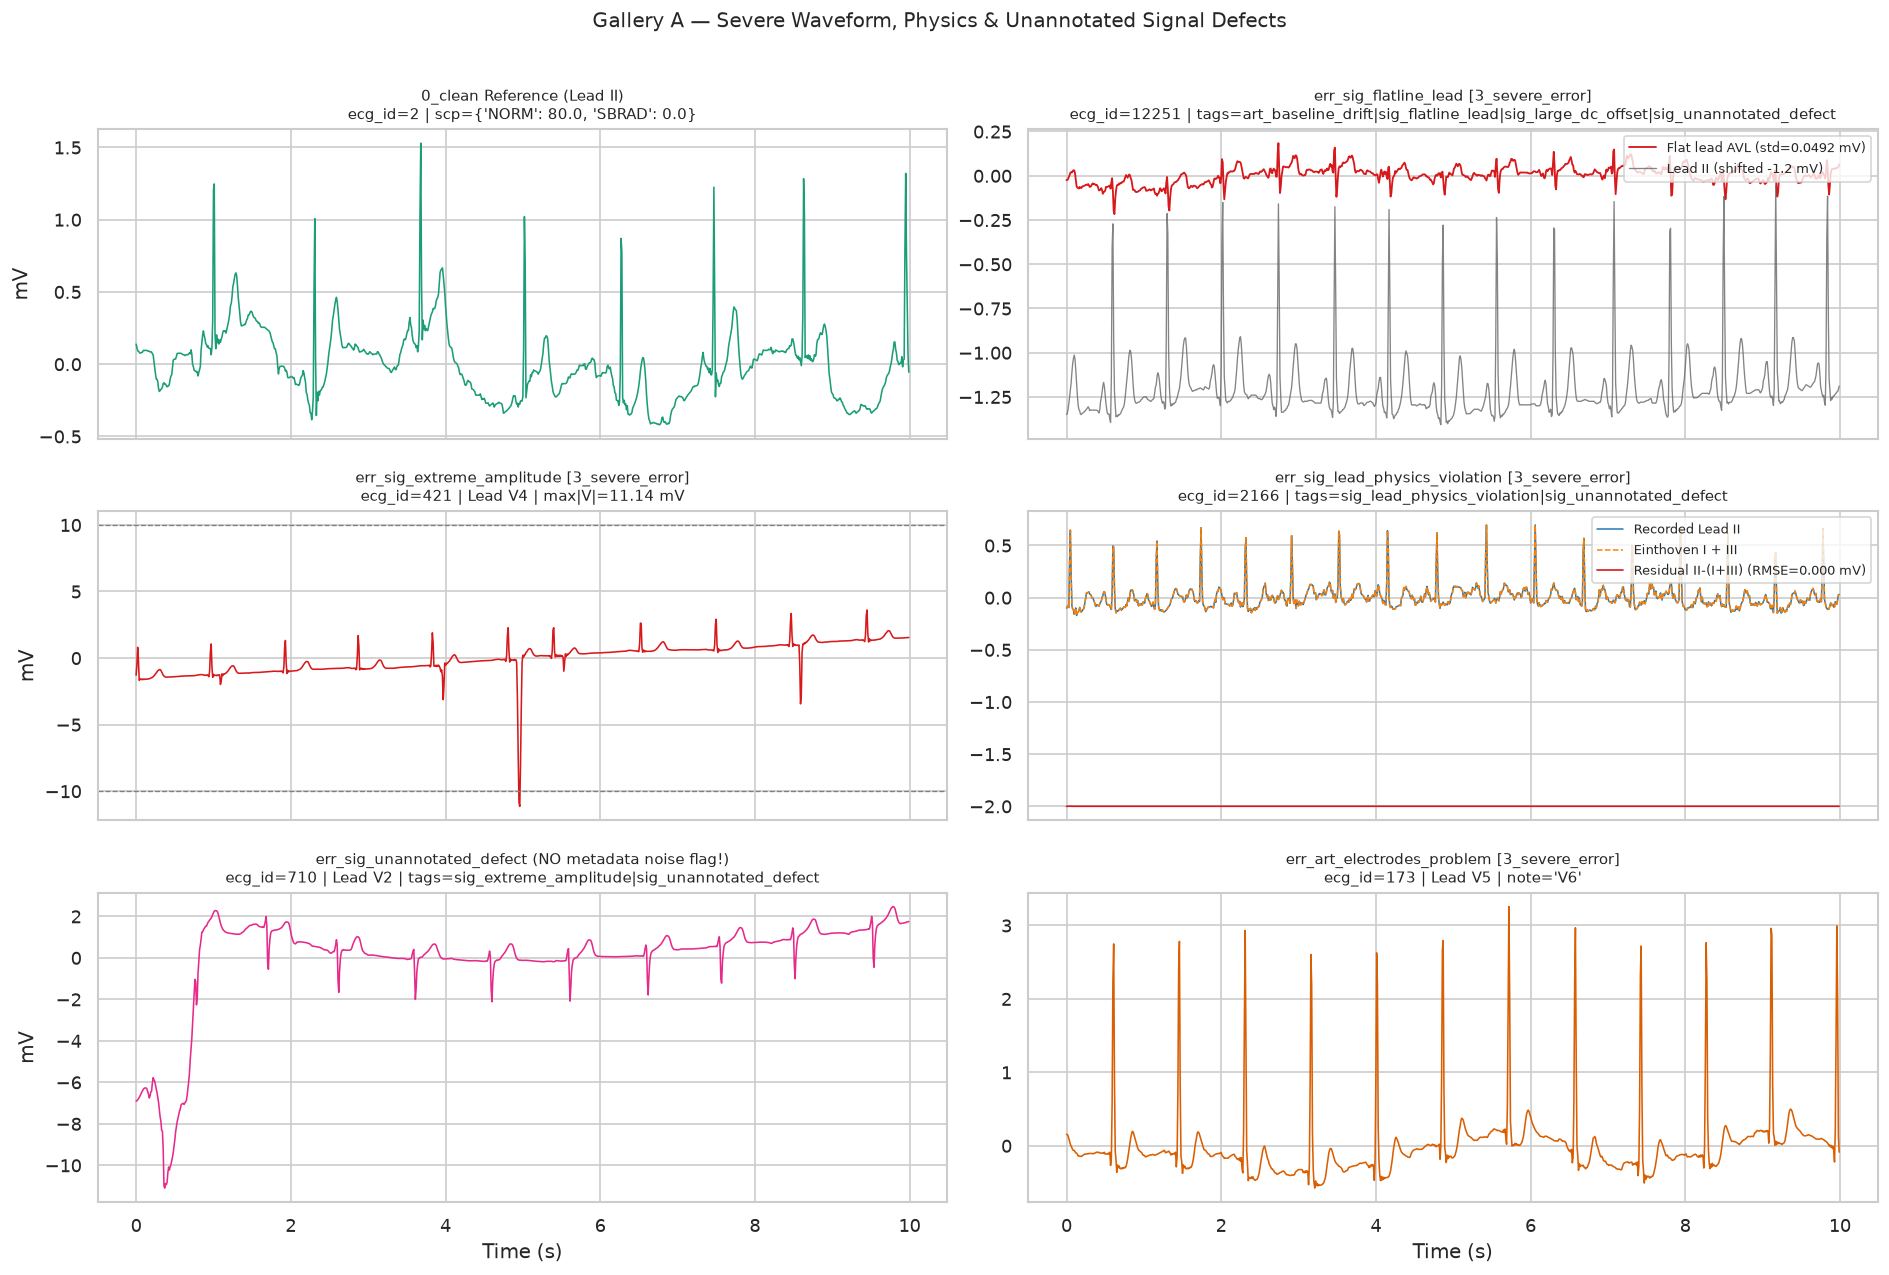

In [6]:
import io
import re
import zipfile
from scipy import signal as sp_signal

LEADS = PTBXLDataset.LEADS

def load_lr(ecg_id: int) -> np.ndarray:
    sig, _ = wfdb.rdsamp(str(DATA_DIR / raw_df.loc[ecg_id, "filename_lr"]))
    return np.nan_to_num(sig)  # (1000, 12)

def first_id(mask: pd.Series) -> int:
    return int(err_df.index[mask][0])

# ── Gallery A: Severe Waveform & Hardware Defects ─────────────────────────
id_clean   = first_id(err_df["severity_tier"] == "0_clean")
id_flat    = first_id(err_df["err_sig_flatline_lead"] == 1)
id_spike   = first_id(err_df["err_sig_extreme_amplitude"] == 1)
id_physics = first_id(err_df["err_sig_lead_physics_violation"] == 1)
id_unannot = first_id((err_df["err_sig_unannotated_defect"] == 1) & (err_df.index != id_flat) & (err_df.index != id_spike))
id_elec    = first_id(err_df["err_art_electrodes_problem"] == 1)

fig, axes = plt.subplots(3, 2, figsize=(16, 10.5), sharex=True)
axes = axes.ravel()
t = np.arange(1000) / 100.0

# 1. Clean reference
s = load_lr(id_clean)
axes[0].plot(t, s[:, 1], color="#1b9e77", lw=0.95)
axes[0].set_title(f"0_clean Reference (Lead II)\necg_id={id_clean} | scp={raw_df.loc[id_clean, 'scp_codes']}", fontsize=9)
axes[0].set_ylabel("mV")

# 2. Flatline lead (pick lead with min std)
s = load_lr(id_flat)
flat_l = int(np.argmin(s.std(axis=0)))
axes[1].plot(t, s[:, flat_l], color="#d7191c", lw=1.1, label=f"Flat lead {LEADS[flat_l]} (std={s[:, flat_l].std():.4f} mV)")
axes[1].plot(t, s[:, 1] - 1.2, color="#666666", lw=0.8, alpha=0.8, label="Lead II (shifted -1.2 mV)")
axes[1].set_title(f"err_sig_flatline_lead [3_severe_error]\necg_id={id_flat} | tags={err_df.loc[id_flat, 'error_tags']}", fontsize=9)
axes[1].legend(fontsize=8, loc="upper right")

# 3. Extreme amplitude (>10 mV)
s = load_lr(id_spike)
spk_l = int(np.argmax(np.abs(s).max(axis=0)))
axes[2].plot(t, s[:, spk_l], color="#d7191c", lw=0.95)
axes[2].axhline(10.0, color="gray", ls="--", lw=0.8)
axes[2].axhline(-10.0, color="gray", ls="--", lw=0.8)
axes[2].set_title(f"err_sig_extreme_amplitude [3_severe_error]\necg_id={id_spike} | Lead {LEADS[spk_l]} | max|V|={np.abs(s[:, spk_l]).max():.2f} mV", fontsize=9)
axes[2].set_ylabel("mV")

# 4. Einthoven lead-physics violation: Lead II vs (I + III) and residual
s = load_lr(id_physics)
recon_ii = s[:, 0] + s[:, 2]
resid = s[:, 1] - recon_ii
axes[3].plot(t, s[:, 1], color="#1f78b4", lw=0.9, label="Recorded Lead II")
axes[3].plot(t, recon_ii, color="#ff7f00", lw=0.9, ls="--", label="Einthoven I + III")
axes[3].plot(t, resid - 2.0, color="#d7191c", lw=1.0, label=f"Residual II-(I+III) (RMSE={np.sqrt(np.mean(resid**2)):.3f} mV)")
axes[3].set_title(f"err_sig_lead_physics_violation [3_severe_error]\necg_id={id_physics} | tags={err_df.loc[id_physics, 'error_tags']}", fontsize=9)
axes[3].legend(fontsize=7.8, loc="upper right")

# 5. Unannotated waveform defect (missed by metadata noise flags!)
s = load_lr(id_unannot)
bad_l = int(np.argmax(np.abs(s).max(axis=0)))
axes[4].plot(t, s[:, bad_l], color="#e7298a", lw=0.95)
axes[4].set_title(f"err_sig_unannotated_defect (NO metadata noise flag!)\necg_id={id_unannot} | Lead {LEADS[bad_l]} | tags={err_df.loc[id_unannot, 'error_tags']}", fontsize=9)
axes[4].set_xlabel("Time (s)")
axes[4].set_ylabel("mV")

# 6. Electrode problem
s = load_lr(id_elec)
elec_l = int(np.argmax(np.abs(s).max(axis=0)))
axes[5].plot(t, s[:, elec_l], color="#d95f02", lw=0.95)
axes[5].set_title(f"err_art_electrodes_problem [3_severe_error]\necg_id={id_elec} | Lead {LEADS[elec_l]} | note={repr(raw_df.loc[id_elec, 'electrodes_problems'])}", fontsize=9)
axes[5].set_xlabel("Time (s)")

fig.suptitle("Gallery A — Severe Waveform, Physics & Unannotated Signal Defects", y=1.01, fontsize=12)
plt.tight_layout()
plt.show()

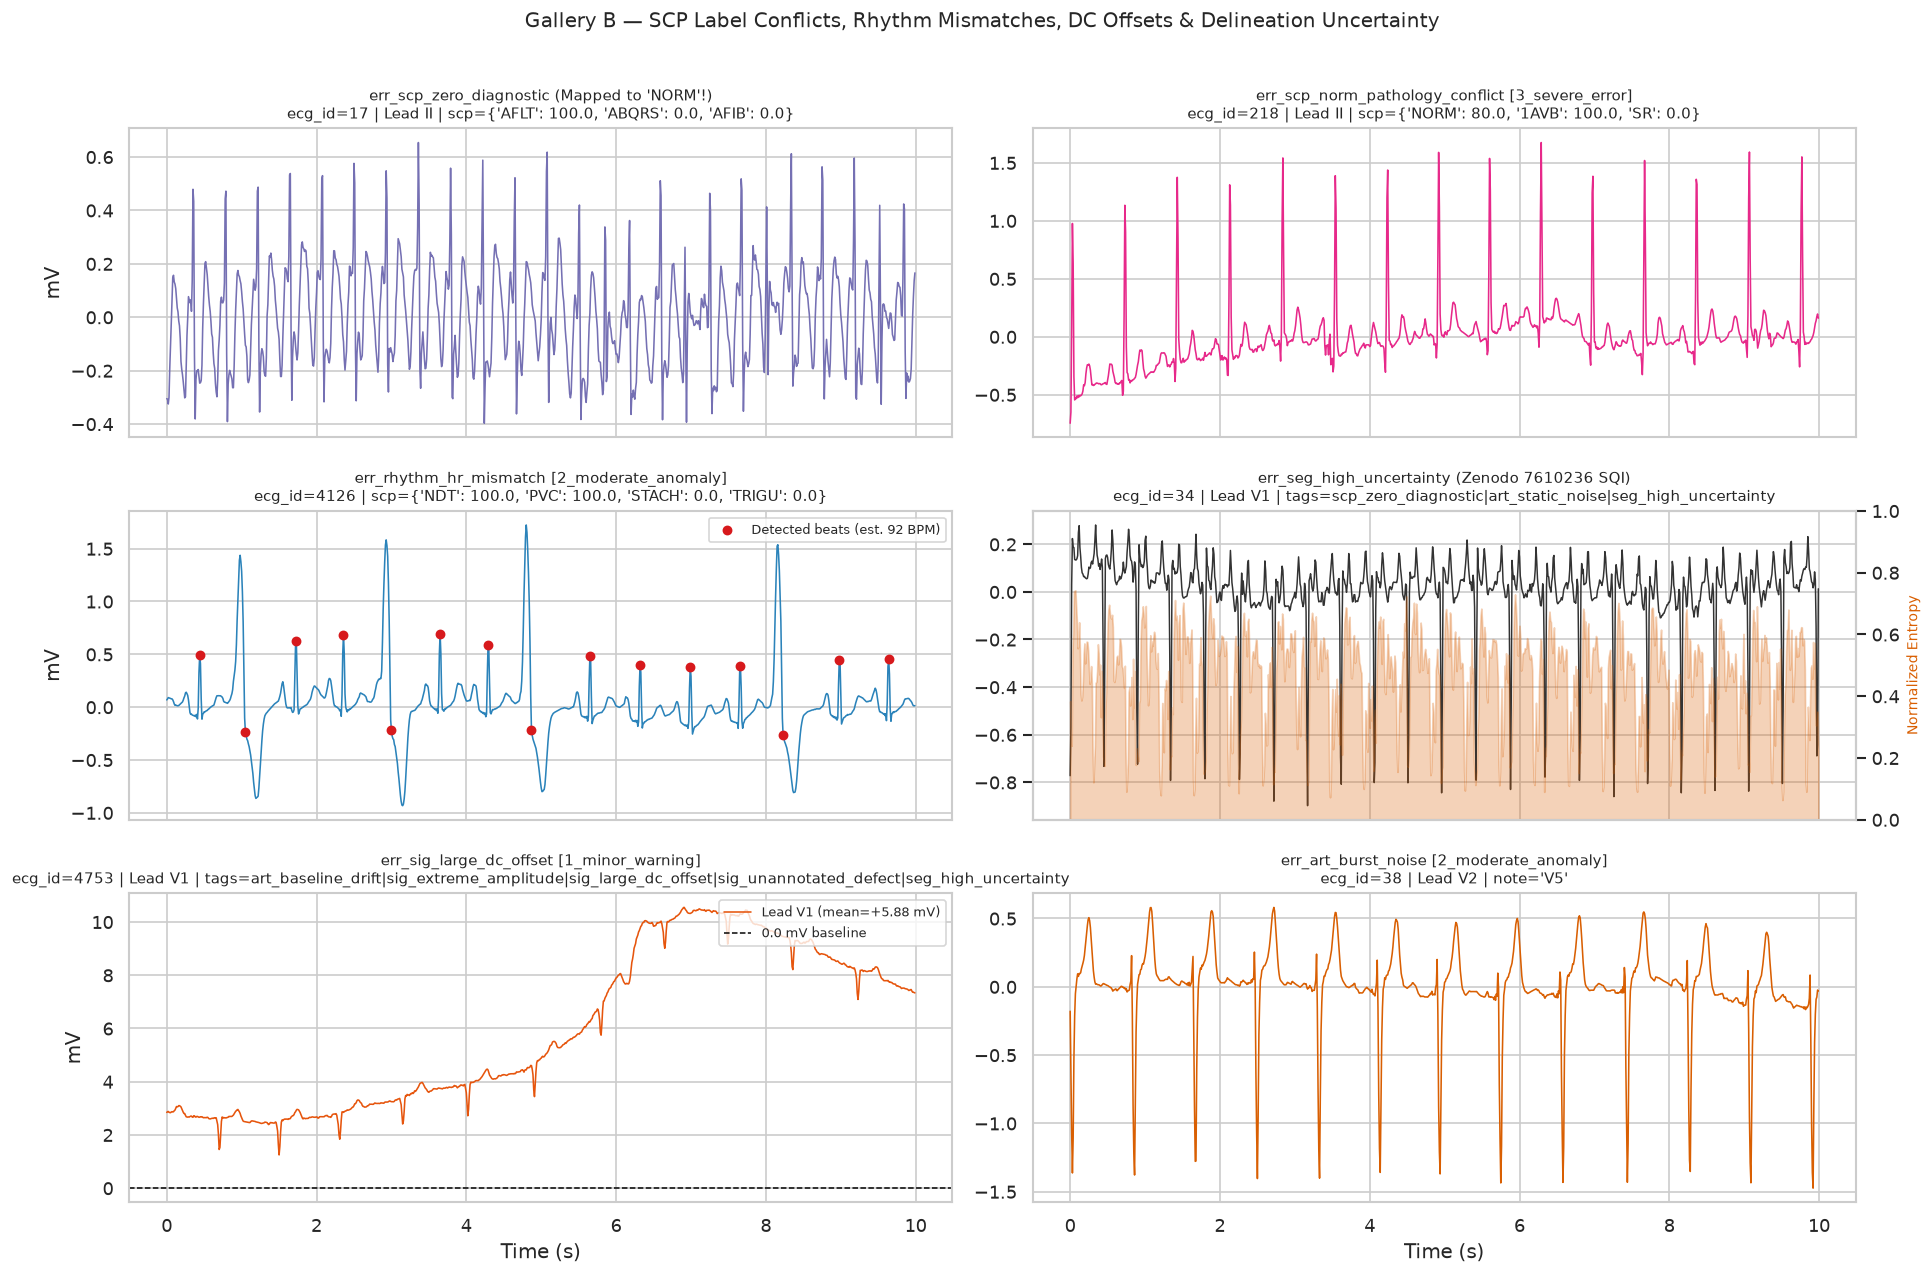

In [7]:
# ── Gallery B: Label, Rhythm, DC Offset & Delineation Anomalies ───────────
id_zero_diag = first_id((err_df["err_scp_zero_diagnostic"] == 1) & raw_df["scp_codes"].str.contains("AFIB|PACE"))
id_norm_conf = first_id(err_df["err_scp_norm_pathology_conflict"] == 1)
id_hr_mis    = first_id(err_df["err_rhythm_hr_mismatch"] == 1)
id_high_ent  = first_id((err_df["err_seg_high_uncertainty"] == 1) & (err_df["err_art_electrodes_problem"] == 0))
id_dc        = first_id(err_df["err_sig_large_dc_offset"] == 1)
id_burst     = first_id((err_df["err_art_burst_noise"] == 1) & (err_df["err_art_electrodes_problem"] == 0))

# Load Zenodo soft-segmentation entropy curve for id_high_ent
seg_zip = DATA_DIR / "ptbxl_segmentations_8bit.zip"
ent_curve = None
ent_lead_idx = 1
if seg_zip.exists():
    with zipfile.ZipFile(seg_zip, "r") as zf:
        target_member = next(
            info.filename for info in zf.infolist()
            if not info.is_dir() and re.match(rf"^0*{id_high_ent}(?:\..+)?$", Path(info.filename).name)
        )
        u8 = np.asarray(np.load(io.BytesIO(zf.read(target_member)), allow_pickle=True), dtype=np.float32)
        probs = u8 / np.maximum(u8.sum(axis=-1, keepdims=True), 1.0)
        ent_all = -np.sum(probs * np.log(np.clip(probs, 1e-8, 1.0)), axis=-1) / np.log(24.0)
        ent_lead_idx = int(np.argmax(ent_all.mean(axis=0)))
        ent_curve = ent_all[:, ent_lead_idx]

fig, axes = plt.subplots(3, 2, figsize=(16, 10.5), sharex=True)
axes = axes.ravel()
t = np.arange(1000) / 100.0

# 1. Zero diagnostic codes mapped to NORM
s = load_lr(id_zero_diag)
axes[0].plot(t, s[:, 1], color="#7570b3", lw=0.95)
axes[0].set_title(f"err_scp_zero_diagnostic (Mapped to 'NORM'!)\necg_id={id_zero_diag} | Lead II | scp={raw_df.loc[id_zero_diag, 'scp_codes']}", fontsize=8.8)
axes[0].set_ylabel("mV")

# 2. NORM + Pathology conflict
s = load_lr(id_norm_conf)
axes[1].plot(t, s[:, 1], color="#e7298a", lw=0.95)
axes[1].set_title(f"err_scp_norm_pathology_conflict [3_severe_error]\necg_id={id_norm_conf} | Lead II | scp={raw_df.loc[id_norm_conf, 'scp_codes']}", fontsize=8.8)

# 3. Rhythm vs Heart Rate mismatch (with detected R-peaks)
s = load_lr(id_hr_mis)
b_qrs, a_qrs = sp_signal.butter(3, [5.0 / 50.0, 20.0 / 50.0], btype="bandpass")
s_ii = s[:, 1] - np.median(s[:, 1])
e_ii = sp_signal.filtfilt(b_qrs, a_qrs, s_ii) ** 2
pks, _ = sp_signal.find_peaks(e_ii, distance=25, height=max(float(np.percentile(e_ii, 85)) * 1.4, 1e-4))
est_bpm = 60.0 / (np.median(np.diff(pks)) / 100.0) if len(pks) >= 2 else np.nan
axes[2].plot(t, s_ii, color="#2b83ba", lw=0.95)
axes[2].scatter(pks / 100.0, s_ii[pks], color="#d7191c", s=24, zorder=3, label=f"Detected beats (est. {est_bpm:.0f} BPM)")
axes[2].set_title(f"err_rhythm_hr_mismatch [2_moderate_anomaly]\necg_id={id_hr_mis} | scp={raw_df.loc[id_hr_mis, 'scp_codes']}", fontsize=8.8)
axes[2].set_ylabel("mV")
axes[2].legend(fontsize=8, loc="upper right")

# 4. High soft-segmentation entropy
s = load_lr(id_high_ent)
axes[3].plot(t, s[:, ent_lead_idx], color="#333333", lw=0.9, label=f"Lead {LEADS[ent_lead_idx]} waveform")
if ent_curve is not None:
    ax3_r = axes[3].twinx()
    ax3_r.fill_between(t, 0, ent_curve, color="#d95f02", alpha=0.28, label=f"24-class entropy (mean={ent_curve.mean():.2f})")
    ax3_r.set_ylim(0, 1.0)
    ax3_r.set_ylabel("Normalized Entropy", color="#d95f02", fontsize=8.5)
    ax3_r.grid(False)
axes[3].set_title(f"err_seg_high_uncertainty (Zenodo 7610236 SQI)\necg_id={id_high_ent} | Lead {LEADS[ent_lead_idx]} | tags={err_df.loc[id_high_ent, 'error_tags']}", fontsize=8.8)

# 5. Large DC baseline offset (> 0.5 mV)
s = load_lr(id_dc)
dc_l = int(np.argmax(np.abs(s.mean(axis=0))))
axes[4].plot(t, s[:, dc_l], color="#e6550d", lw=0.95, label=f"Lead {LEADS[dc_l]} (mean={s[:, dc_l].mean():+.2f} mV)")
axes[4].axhline(0.0, color="black", ls="--", lw=0.9, label="0.0 mV baseline")
axes[4].set_title(f"err_sig_large_dc_offset [1_minor_warning]\necg_id={id_dc} | Lead {LEADS[dc_l]} | tags={err_df.loc[id_dc, 'error_tags']}", fontsize=8.8)
axes[4].set_xlabel("Time (s)")
axes[4].set_ylabel("mV")
axes[4].legend(fontsize=8, loc="upper right")

# 6. Burst noise artifact
s = load_lr(id_burst)
burst_l = int(np.argmax(np.abs(s).max(axis=0)))
axes[5].plot(t, s[:, burst_l], color="#d95f02", lw=0.95)
axes[5].set_title(f"err_art_burst_noise [2_moderate_anomaly]\necg_id={id_burst} | Lead {LEADS[burst_l]} | note={repr(raw_df.loc[id_burst, 'burst_noise'])}", fontsize=8.8)
axes[5].set_xlabel("Time (s)")

fig.suptitle("Gallery B — SCP Label Conflicts, Rhythm Mismatches, DC Offsets & Delineation Uncertainty", y=1.01, fontsize=12)
plt.tight_layout()
plt.show()